# Objetivos: 

 - Conectar com o STAC;
 - Pegar o NDVI do Sentinel;
 - Geras geometrias a partir dos pixels de alto NDVI;
 - Tudo deve ser parametrizado;


In [3]:
import numpy as np 
import rasterio as rio 
import pystac_client 
import matplotlib.pyplot as plt
from shapely.geometry import Point
from shapely.ops import unary_union
import glob
import geopandas as gpd

/home/william/Desktop/POC_otmização/env/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Import Data

In [2]:
URL = 'https://data.inpe.br/bdc/stac/v1/' 
service = pystac_client.Client.open(URL)

In [3]:
import collections
search = service.search(
    collections=["S2_L2A-1"],
    # tile 21KWT
    query={"eo:cloud_cover": {"lt": 10}, 
            "tileId": {"eq": "21KWT"}},
    datetime="2024-08-04/2024-09-04",
    method = "POST"
)

/tmp/ipykernel_57067/973445588.py:2: PystacClientWarning: The requested method 'POST' is not advertised by any root catalog search link. Available methods: GET
  search = service.search(


#### Disponíveis

In [4]:
items = search.item_collection()
[item.id for item in items]

['S2A_MSIL2A_20240904T134701_N0511_R024_T21KWT_20240904T221048',
 'S2B_MSIL2A_20240902T135709_N0511_R067_T21KWT_20240902T180147',
 'S2B_MSIL2A_20240830T134709_N0511_R024_T21KWT_20240830T193857',
 'S2A_MSIL2A_20240828T135701_N0511_R067_T21KWT_20240828T195445',
 'S2B_MSIL2A_20240820T134709_N0511_R024_T21KWT_20240820T192429',
 'S2A_MSIL2A_20240818T135701_N0511_R067_T21KWT_20240818T212251',
 'S2A_MSIL2A_20240815T134711_N0511_R024_T21KWT_20240815T205852',
 'S2B_MSIL2A_20240810T134709_N0511_R024_T21KWT_20240810T174637',
 'S2A_MSIL2A_20240805T134711_N0511_R024_T21KWT_20240805T220955']

In [5]:
print(f"Bandas disponíveis: {items[2].assets.keys()}")
print(f"URL da Banda 08A (NIR): {items[2].assets["B8A"].href}")
print(f"URL da Banda 12A (SWIR): {items[2].assets["B12"].href}")

Bandas disponíveis: dict_keys(['AOT', 'B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B09', 'B11', 'B12', 'B8A', 'PVI', 'SCL', 'TCI', 'WVP', 'MTD_TL', 'thumbnail'])
URL da Banda 08A (NIR): https://data.inpe.br/bdc/data/S2_L2A/v001/21/K/WT/2024/08/S2B_B8A_20240830T134709_N0511_R024_T21KWT_20240830T193857.tif
URL da Banda 12A (SWIR): https://data.inpe.br/bdc/data/S2_L2A/v001/21/K/WT/2024/08/S2B_B12_20240830T134709_N0511_R024_T21KWT_20240830T193857.tif


### Tracking

In [6]:
NIR = items[2].assets["B8A"].href
SWIR = items[2].assets["B12"].href

In [7]:
with rio.open(NIR) as src_nir:
    profile = src_nir.profile
    nir = src_nir.read(1).astype("float32")

In [8]:
with rio.open(SWIR) as src_swir:
    swir = src_swir.read(1).astype("float32")

In [9]:
denominador = nir + swir
nbr = np.where(denominador == 0, np.nan, (nir - swir) / denominador)

/tmp/ipykernel_57067/2990669515.py:2: RuntimeWarning: invalid value encountered in divide
  nbr = np.where(denominador == 0, np.nan, (nir - swir) / denominador)


##### View

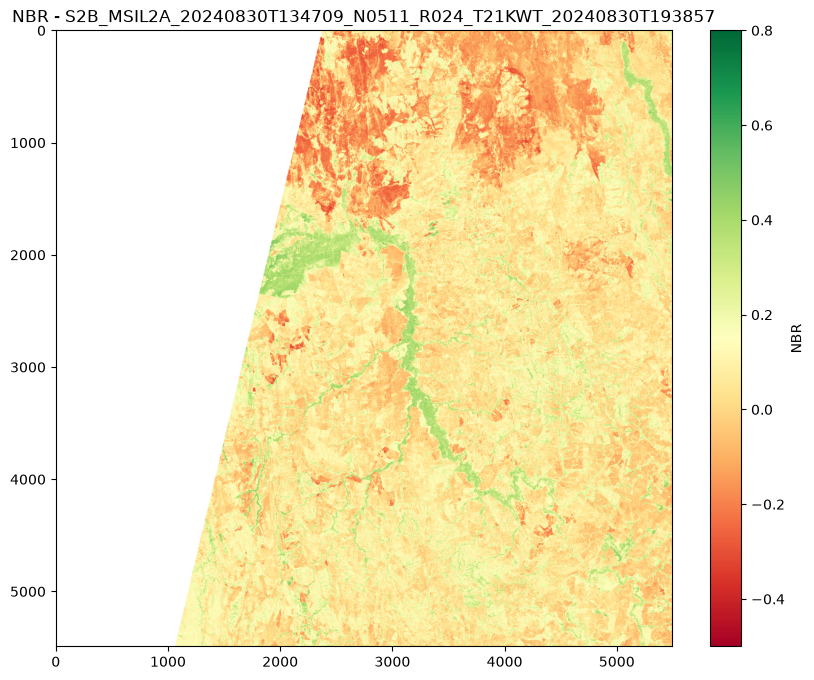

In [10]:
plt.figure(figsize=(10, 8))
# Usando colormapRdYlGn invertido ou YlOrBr (comum para queimadas)
plt.imshow(nbr, cmap="RdYlGn", vmin=-0.5, vmax=0.8)
plt.colorbar(label="NBR")
plt.title(f"NBR - {items[2].id}")
plt.show()


## Gerar a Geometria

#### Pré config

In [11]:
LIMIAR_NBR = -0.15     # Pixels com NBR menor que isso são considerados queimada
TAMANHO_BUFFER = 20    # Raio em metros do buffer quadrado (Sentinel-2 B8A/B12 tem 20m)
UNIR_VIZINHOS = True  

### Filter (Terei que mudar para 1 pois imagem virá com 0 e 1)

In [12]:
linhas, colunas = np.where(nbr < LIMIAR_NBR)
print(f"Pixels detectados como queimada: {len(linhas)}")

Pixels detectados como queimada: 1090872


##### Refs da cena

In [13]:
transform = profile["transform"]
crs = profile["crs"]

### Gerando geometrias dado .tiff

In [8]:
import os
import rioxarray
import rasterio.features
from shapely.geometry import shape

In [9]:
arquivos_to_mask = glob.glob(os.path.join(os.getcwd(), "*.tif"))

In [16]:
if arquivos_to_mask:
    print(f"Carregando {len(arquivos_to_mask)} arquivos de máscara...")
    for i,arq in enumerate(arquivos_to_mask):
        name = arq
        name = name.split('/')
        raster = rioxarray.open_rasterio(arq)
        banda = raster[0].values
        dfs = raster.to_dataframe(name='value').reset_index()

        mask = (banda == 1)

        transform = raster.rio.transform()
        crs = raster.rio.crs

        gerador_shapes = rasterio.features.shapes(
            banda, 
            mask=mask,      # Só gera polígonos onde a máscara for Verdadeira
            transform=transform
        )
        
        geometrias = []
        valores = []

        for geom, valor in gerador_shapes:
            geometrias.append(shape(geom))
            valores.append(valor)

        gdf_poligonos = gpd.GeoDataFrame(
            {'valor_pixel': valores}, 
            geometry=geometrias, 
            crs=crs
        )
        
        # Concatena e projeta para CRS métrico EPSG:5880 (área em m²)
        poligonos_queimadas = gdf_poligonos.to_crs(epsg=5880)

        nome_saida = f'{name[6]}.geojson'
        poligonos_queimadas.to_file(nome_saida, driver="GeoJSON")
        print(f"Salvo: {nome_saida}")

else:
    print("Aviso: Nenhum arquivo .tif encontrado.")

Carregando 3 arquivos de máscara...
Salvo: queimadas_retangulo_serie_20240803_20240904.tif.geojson
Salvo: queimadas_pantanal_gpkg_20250803_20250904.tif.geojson
Salvo: queimadas_pantanal_gpkg_20240803_20240904.tif.geojson


### Gerando geomatrias

In [14]:
lat, long = rio.transform.xy(transform, linhas, colunas, offset="center")
pontos = [Point(x, y) for x, y in zip(lat, long)]

In [15]:
buffers_quadrados = [
    p.buffer(TAMANHO_BUFFER, cap_style="square") for p in pontos
]

In [16]:
if UNIR_VIZINHOS and len(buffers_quadrados) > 0:
    # Une todos os quadrados que se tocam em polígonos
    geometrias_unidas = unary_union(buffers_quadrados)
    
    if geometrias_unidas.geom_type == "MultiPolygon":
        geometrias_finais = list(geometrias_unidas.geoms)
    else:
        geometrias_finais = [geometrias_unidas]
        
    gdf_queimadas = gpd.GeoDataFrame(
        {"id_poligono": range(len(geometrias_finais))},
        geometry=geometrias_finais,
        crs=crs
    )
else:
    gdf_queimadas = gpd.GeoDataFrame(geometry=buffers_quadrados, crs=crs)
# Área Km²
gdf_queimadas["area_km"] = gdf_queimadas.geometry.area / 1e6
print(f"Total de polígonos de queimada gerados: {len(gdf_queimadas)}")
gdf_queimadas.head()


Total de polígonos de queimada gerados: 10377


,id_poligono,geometry,area_km
0,0,"POLYGON ((533150 7697810, 533150 7697830, 5331...",0.0056
1,1,"POLYGON ((533190 7697910, 533210 7697910, 5332...",0.0024
2,2,"POLYGON ((533670 7699390, 533670 7699410, 5337...",0.0812
3,3,"POLYGON ((533950 7699810, 533950 7699790, 5339...",0.0076
4,4,"POLYGON ((533870 7699850, 533870 7699830, 5338...",0.0052


#### View scene

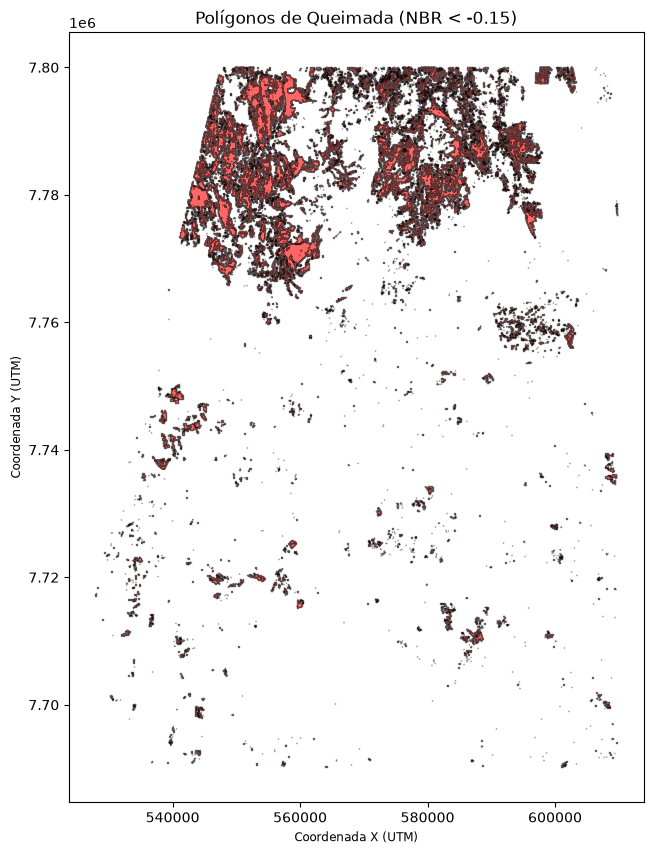

In [17]:

fig, ax = plt.subplots(figsize=(10, 10))
# Plota os polígonos de queimada
gdf_queimadas.plot(ax=ax, color="red", edgecolor="black", alpha=0.6)
ax.set_title(f"Polígonos de Queimada (NBR < {LIMIAR_NBR})")
ax.set_xlabel("Coordenada X (UTM)")
ax.set_ylabel("Coordenada Y (UTM)")
plt.show()

In [27]:
bbox= gpd.read_file('../bboxPanatanal.gpkg')
bbox.to_crs(4326, inplace=True)
box=bbox.total_bounds

## Save

In [18]:
gdf_queimadas.to_file("poligonos_queimadas_nbr_teste.geojson", driver="GeoJSON")
